# **Importação das Bibliotecas**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

# **Carregamento e Exploração dos Dados**

In [2]:
# Carregar a base Iris
iris = load_iris()
X = iris.data
y = iris.target

# Criar DataFrame para visualização
df = pd.DataFrame(X, columns=iris.feature_names)
df['target'] = y
df['classe'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})

print("Shape do dataset:", df.shape)
print("\nPrimeiras linhas:")
print(df.head())
print("\nDistribuição das classes:")
print(df['classe'].value_counts())
print("\nEstatísticas descritivas:")
print(df.describe())

Shape do dataset: (150, 6)

Primeiras linhas:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  classe  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  

Distribuição das classes:
classe
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Estatísticas descritivas:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066  

#  **Divisão Treino/Teste e Normalização**

In [3]:
# Divisão estratificada 70/30
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Normalização — importante para KNN (baseado em distância)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Treino: {X_train_scaled.shape[0]} amostras")
print(f"Teste:  {X_test_scaled.shape[0]} amostras")

Treino: 105 amostras
Teste:  45 amostras


# **Treinamento do Modelo KNN**

In [10]:
# Instanciar o classificador KNN
knn = KNeighborsClassifier(
    n_neighbors=5,        # número de vizinhos
    weights='uniform',    # 'uniform' ou 'distance'
    metric='minkowski',   # distância de Minkowski (p=2 → Euclidiana)
    p=2
)

# Treinar o modelo
knn.fit(X_train_scaled, y_train)



KNeighborsClassifier()

# **Previsões**

In [11]:
# Previsões no conjunto de teste
y_pred = knn.predict(X_test_scaled)

# Probabilidades associadas a cada classe
y_proba = knn.predict_proba(X_test_scaled)

print("Previsões:")
print(y_pred)
print("\nValores reais:")
print(y_test)

print("\nPrimeiras 5 previsões com probabilidades:")
for i in range(5):
    print(f"Amostra {i+1}: predito={iris.target_names[y_pred[i]]:10s} | "
          f"real={iris.target_names[y_test[i]]:10s} | " )

Previsões:
[2 1 1 1 2 2 1 1 0 2 0 0 2 2 0 2 1 0 0 0 1 0 1 2 1 1 1 1 1 0 1 2 1 0 2 0 0
 0 0 1 1 0 1 2 1]

Valores reais:
[2 1 2 1 2 2 1 1 0 2 0 0 2 2 0 2 1 0 0 0 1 0 1 2 2 1 1 1 1 0 2 2 1 0 2 0 0
 0 0 1 1 0 2 2 1]

Primeiras 5 previsões com probabilidades:
Amostra 1: predito=virginica  | real=virginica  | 
Amostra 2: predito=versicolor | real=versicolor | 
Amostra 3: predito=versicolor | real=virginica  | 
Amostra 4: predito=versicolor | real=versicolor | 
Amostra 5: predito=virginica  | real=virginica  | 


# **Métricas de Classificação**

In [12]:
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall    = recall_score(y_test, y_pred, average='weighted')
f1        = f1_score(y_test, y_pred, average='weighted')

print("=" * 55)
print("MÉTRICAS DE CLASSIFICAÇÃO — KNN (scikit-learn)")
print("=" * 55)
print(f"Acurácia:  {accuracy:.4f}")
print(f"Precisão:  {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nRelatório completo:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

MÉTRICAS DE CLASSIFICAÇÃO — KNN (scikit-learn)
Acurácia:  0.9111
Precisão:  0.9298
Recall:    0.9111
F1-Score:  0.9095

Relatório completo:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.79      1.00      0.88        15
   virginica       1.00      0.73      0.85        15

    accuracy                           0.91        45
   macro avg       0.93      0.91      0.91        45
weighted avg       0.93      0.91      0.91        45



# **Matriz de Confusão**

Matriz de Confusão:
[[15  0  0]
 [ 0 15  0]
 [ 0  4 11]]


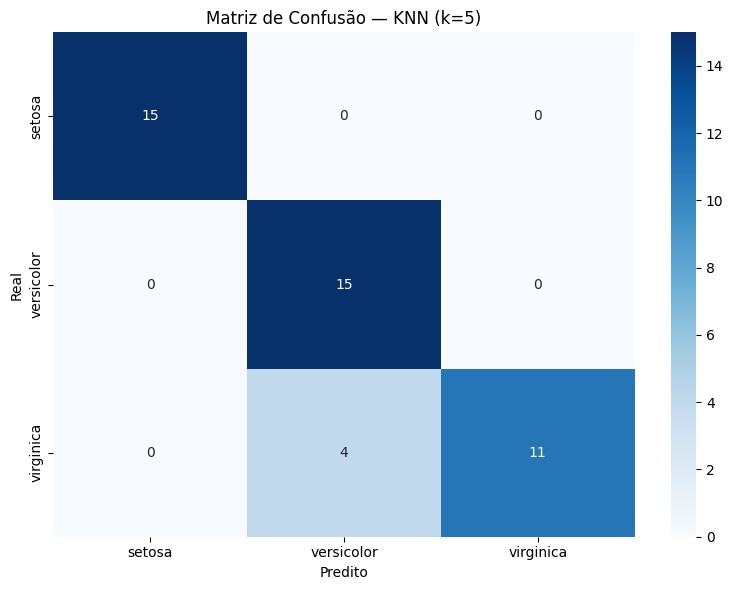

In [13]:
cm = confusion_matrix(y_test, y_pred)

print("Matriz de Confusão:")
print(cm)

# Visualização
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.title('Matriz de Confusão — KNN (k=5)')
plt.xlabel('Predito')
plt.ylabel('Real')
plt.tight_layout()
plt.show()